# 11 — Who will be Most Improved in 2026-27? A preseason top 7

**Question.** Before a game has been played, who are our seven most likely Most Improved Player (MIP) winners for 2026-27? The top pick is our MIP prediction; the other six are the breakout candidates.

Notebook 10 named the winner *after* the season, from how much each player's numbers had changed. Here none of those changes exist yet. All we have is **last season** and **this preseason so far**.

**The problem with preseason.** Minutes are not real. Stars sit, deep-bench players get long runs, and a 6-minute player who gets 24 preseason minutes will not keep them. So:

**Decisions**
- **Performance is per 36 minutes, never totals.** Preseason form = his preseason rate (points, game score, shot volume per 36; true shooting) minus the same rate last season.
- **Small samples are shrunk.** Each preseason change is multiplied by *minutes ÷ (minutes + 150)*: 50 preseason minutes count for a quarter, 150 for half.
- **Centred within each preseason,** so the league-wide gap between preseason and regular-season basketball drops out.
- **Preseason minutes: option (b).** Increases count, decreases are ignored (a rested veteran's low minutes say nothing). Tested below, and kept only if it helps.
- **Baseline season** as in notebook 10: the most recent season with at least 33% of the games played.
- **Who is a candidate:** anyone with a baseline season and preseason minutes. No exclusions: previous winners and established scorers are included (revised 30 October; see 11B).
- **Established scorers are handled by a scoring turning point,** not a rule: points last season count slightly in a player's favour up to a turning point and against him above it (he is MVP material, not MIP). The turning point is chosen by backtest (11B): **20 points a game**.
- **A star left his team:** 1 if a player who scored 20+ points a game for his team last season has been seen with another team in preseason, and no 20+ scorer has joined. Added 30 October from notebook 14 (decision D29).
- **Model:** the same choice model as notebook 10 (one winner per season, chances add up to 100%), trained on the 14 preseasons from 2012-13 to 2025-26. Voting results are not used.

**Data:** the complete 2026-27 preseason (67 games, 3–16 October). An earlier version of this notebook used games through 12 October and excluded previous winners and 22+ point scorers; its top 7 was Reed Sheppard, Stephon Castle, Ty Jerome, Rui Hachimura, Amen Thompson, Leonard Miller and Tristan da Silva.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from unicorn.labels import MIP_WINNERS
from unicorn.mip import ChoiceModel
from unicorn.plotting import apply_style, BLUE, ORANGE, INK, INK2, MUTED, FIG_DIR, SURFACE
from unicorn.preseason import (load_preseason, preseason_frame, regular_rates, add_pool_flags, SHRINK_MINUTES,
                               LAST_SEASON_LEAN, PROFILE, MOMENTUM, PRE_FORM_LEAN, PRE_MINUTES, LEAN,
                               LAST_SEASON, PRE_FORM, USED, TURN, TURNING_POINT, TEAM_CHANGE, add_turning_point, add_star_left, preseason_opportunity)
from unicorn.raw import PROJECT_ROOT

warnings.filterwarnings("ignore")
apply_style()
TARGET = "2026-27"
regular = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_games.parquet")
player_season = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
pre = load_preseason(regular=regular, refresh_latest=False)   # set refresh_latest=True to pull the newest preseason games

frame = add_pool_flags(preseason_frame(pre, regular, player_season), MIP_WINNERS)
frame = add_turning_point(frame).merge(preseason_opportunity(pre, regular), on=["player_id", "season_start"], how="left")
frame["opportunity"] = frame["opportunity"].fillna(0)
frame = add_star_left(frame, pre, regular)
now = pre[pre["season"] == TARGET]
print(f"preseason player-games: {len(pre):,} over {pre['season'].nunique()} preseasons")
print(f"{TARGET} preseason so far: {len(now):,} player-games, {now['game_id'].nunique()} games, through {now['game_date'].max():%d %b %Y}")
print(f"player-seasons with a baseline season and preseason minutes: {len(frame):,}; median preseason minutes {frame['pre_minutes'].median():.0f}")

preseason player-games: 33,772 over 15 preseasons
2026-27 preseason so far: 1,991 player-games, 67 games, through 16 Oct 2026
player-seasons with a baseline season and preseason minutes: 5,632; median preseason minutes 76


## 11A — How much of preseason carries into the season?

Before using preseason numbers, check what they have been worth in the past 14 seasons. Players with at least 60 preseason minutes who then played 20+ regular-season games.

In [2]:
actual = regular_rates(regular).rename(columns={"mpg": "mpg_act", "pts36": "pts36_act", "game_score36": "game_score36_act",
                                                "volume36": "volume36_act", "ts": "ts_act", "games": "games_act"})
D = frame[frame["season"] != TARGET].merge(actual[["player_id", "season_start", "games_act", "mpg_act", "pts36_act", "game_score36_act", "volume36_act", "ts_act"]],
                                           on=["player_id", "season_start"])
D = D[(D["pre_minutes"] >= 60) & (D["games_act"] >= 20)].copy()
D["mpg_change_act"] = D["mpg_act"] - D["mpg_last"]
bins = [-99, -10, -5, -2, 2, 5, 10, 99]
names = ["down 10+", "down 5 to 10", "down 2 to 5", "within 2", "up 2 to 5", "up 5 to 10", "up 10+"]
D["minutes_bin"] = pd.cut(D["pre_minutes_change_raw"], bins, labels=names)
minutes_table = D.groupby("minutes_bin", observed=True).agg(players=("player_id", "size"), preseason_change=("pre_minutes_change_raw", "mean"),
                                                             season_change=("mpg_change_act", "mean"))
minutes_table["share that carried over"] = minutes_table["season_change"] / minutes_table["preseason_change"]
minutes_table.loc["within 2", "share that carried over"] = np.nan
minutes_table.round(2)

,players,preseason_change,season_change,share that carried over
minutes_bin,,,,
down 10+,540,-12.32,-2.64,0.21
down 5 to 10,940,-7.48,-1.91,0.26
down 2 to 5,514,-3.46,-0.67,0.19
within 2,596,-0.03,0.70,NaN
up 2 to 5,314,3.40,2.52,0.74
up 5 to 10,300,7.18,4.29,0.60
up 10+,138,13.15,8.42,0.64


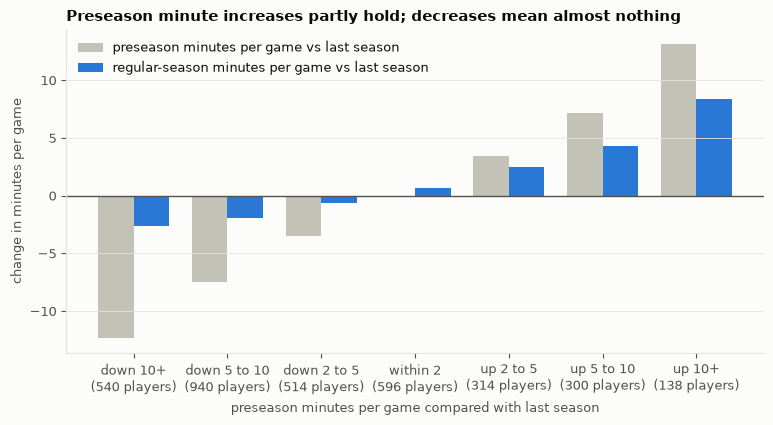

In [3]:
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(minutes_table)); w = 0.38
ax.bar(x - w / 2, minutes_table["preseason_change"], w, color=MUTED, label="preseason minutes per game vs last season")
ax.bar(x + w / 2, minutes_table["season_change"], w, color=BLUE, label="regular-season minutes per game vs last season")
ax.axhline(0, color=INK2, linewidth=1)
ax.set_xticks(x, [f"{n}\n({int(c):,} players)" for n, c in zip(minutes_table.index, minutes_table["players"])])
ax.set_xlabel("preseason minutes per game compared with last season"); ax.set_ylabel("change in minutes per game")
ax.grid(axis="x", visible=False); ax.legend(frameon=False, loc="upper left")
ax.set_title("Preseason minute increases partly hold; decreases mean almost nothing", loc="left")
fig.savefig(FIG_DIR / "11_preseason_minutes_carry_over.png", dpi=150, bbox_inches="tight")

In [4]:
bench = D[(D["mpg_last"] < 12) & (D["pre_mpg"] >= 20)]
print(f"bench players (< 12 min last season) given 20+ preseason minutes a game: {len(bench)}")
print(f"  last season {bench['mpg_last'].mean():.1f} → preseason {bench['pre_mpg'].mean():.1f} → regular season {bench['mpg_act'].mean():.1f} minutes per game; "
      f"{(bench['mpg_act'] >= 20).mean():.0%} kept 20+")

rows = []
for stat, label in [("volume36", "shot volume per 36"), ("pts36", "points per 36"), ("game_score36", "game score per 36"), ("ts", "true shooting %")]:
    pre_change = D[stat] - D[f"{stat}_last"]
    act_change = D[f"{stat}_act"] - D[f"{stat}_last"]
    ok = pre_change.notna() & act_change.notna()
    shrunk = pre_change * D["pre_reliability"]
    rows.append({"per-minute measure": label, "correlation: preseason change vs season change": np.corrcoef(pre_change[ok], act_change[ok])[0, 1],
                 "after shrinking by preseason minutes": np.corrcoef(shrunk[ok], act_change[ok])[0, 1],
                 "share of a preseason gain that shows up in the season": np.polyfit(pre_change[ok], act_change[ok], 1)[0]})
pd.DataFrame(rows).set_index("per-minute measure").round(2)

bench players (< 12 min last season) given 20+ preseason minutes a game: 98
  last season 9.5 → preseason 22.8 → regular season 17.7 minutes per game; 36% kept 20+


,correlation: preseason change vs season change,after shrinking by preseason minutes,share of a preseason gain that shows up in the season
per-minute measure,,,
shot volume per 36,0.51,0.52,0.37
points per 36,0.41,0.42,0.25
game score per 36,0.35,0.35,0.18
true shooting %,0.26,0.27,0.12


### 11A findings

**Minutes**
- **Increases hold at about 60–75%.** Players given 5–10 more preseason minutes than last season kept +4.3 of +7.2; those given 10+ more kept +8.4 of +13.2.
- **Decreases mean almost nothing.** Players down 10+ minutes in preseason lost only 2.6 in the season (about 20%). That is rest, not a smaller role. This is why option (b) ignores decreases.
- **The "6-minute guy playing 24" case:** 98 bench players (under 12 minutes last season) were given 20+ preseason minutes. They went 9.5 → 22.8 → **17.7** minutes per game, and only **36%** kept 20+. A real bump, but nowhere near the preseason number.

**Per-minute form**
- **Shot volume is the most trustworthy preseason signal** (correlation 0.51 with the real change; 37% of a preseason gain shows up in the season). A player taking more shots per minute in preseason usually has a bigger role coming.
- **Points per 36** follow (0.41; 25% shows up). **Game score per 36** is weaker (0.35; 18%).
- **Shooting efficiency is mostly noise** (0.26; 12% shows up). A hot preseason shooting stretch rarely lasts.
- **Shrinking by minutes barely changes these correlations** in this sample, because everyone here already has 60+ minutes. It matters for the players below that, which is where every 2026-27 player is today.

## 11B — Does preseason information help pick the winner?

Every season is predicted by a model that never saw it. Inputs are added in steps, so each step shows what it buys.

- **Last season:** minutes, points, usage, team win %.
- **Profile:** age, second-year player, new team.
- **Momentum:** did he improve last season; did he finish it stronger than he started (after vs before the All-Star break).
- **Preseason form per 36:** game score, shot volume, true shooting (from 11A).

- **Scoring turning point:** points above the turning point last season (see below).
- **A star left his team, and wasn't replaced** (from notebook 14). Compared below with your four-band version and a graded version.
- Tested and reported, then left out if they add nothing: **preseason minute increases** (option b) and **opportunity** (share of the team's minutes freed up over the summer, read from preseason rosters only).

**Who is a candidate:** everyone. Previous winners stay in (nothing bars a second award; the model simply has no repeat winner to learn from). Established scorers stay in, and the turning point decides how much their scoring counts against them. The highest scoring average of any winner the season before is 20.3 (Tyrese Maxey).

In [5]:
# everyone with a baseline season and preseason minutes is a candidate: no exclusions (previous winners and established scorers included)
print("highest last-season scoring average of any eventual winner:", frame.loc[frame["mip"], "ppg_last"].max().round(1))
H = frame[frame["season"] != TARGET].reset_index(drop=True)
print(f"{H['season'].nunique()} seasons, {len(H):,} candidates ({H.groupby('season').size().min()}–{H.groupby('season').size().max()} a season), "
      f"{int(H['mip'].sum())} eventual winners in the pool")

def winner_ranks(features, l2, scheme="loso", min_train=5):
    """Rank of the eventual winner in each season, predicted by a model that never saw that season."""
    out = {}
    seasons = sorted(H["season"].unique())
    for i, s in enumerate(seasons):
        train = H[H["season"] < s] if scheme == "walk_forward" else H[H["season"] != s]
        if scheme == "walk_forward" and i < min_train:
            continue
        test = H[H["season"] == s]
        p = ChoiceModel(features, l2).fit(train).predict_proba(test)
        out[s] = {"rank": int(p.rank(ascending=False, method="min")[test["mip"]].iloc[0]), "p": p[test["mip"]].iloc[0], "n": len(test),
                  "top_pick": test.loc[p.idxmax(), "player_name"], "top7": list(test.loc[p.nlargest(7).index, "player_id"])}
    return pd.DataFrame(out).T

def scorecard(r):
    rk = r["rank"].astype(int)
    return {"seasons": len(r), "winner #1": (rk == 1).sum(), "in top 3": (rk <= 3).sum(), "in top 7": (rk <= 7).sum(), "in top 20": (rk <= 20).sum(),
            "median rank": rk.median(), "times better than a blind guess": np.exp(np.mean(np.log(r["p"].astype(float) * r["n"].astype(float))))}

L2 = 3.0
STEPS = {"last season + profile": LAST_SEASON_LEAN + PROFILE,
         "+ momentum (last season's trend)": LAST_SEASON_LEAN + PROFILE + MOMENTUM,
         "+ preseason form per 36": LEAN,
         f"+ scoring turning point at {TURNING_POINT}": LEAN + TURN,
         "+ a 20-point scorer left his team (not replaced)  ← used": USED,
         "+ preseason minute increases (option b)": USED + PRE_MINUTES,
         "+ opportunity (team minutes freed up)": USED + ["opportunity"]}
ranks = {k: winner_ranks(f, L2) for k, f in STEPS.items()}
table = pd.DataFrame({k: scorecard(r) for k, r in ranks.items()}).T
table.loc["used model, trained on earlier seasons only"] = scorecard(winner_ranks(USED, L2, scheme="walk_forward"))
table.loc["+ opportunity, trained on earlier seasons only"] = scorecard(winner_ranks(USED + ["opportunity"], L2, scheme="walk_forward"))
table.round(1)

highest last-season scoring average of any eventual winner: 20.3
14 seasons, 5,230 candidates (345–398 a season), 14 eventual winners in the pool


,seasons,winner #1,in top 3,in top 7,in top 20,median rank,times better than a blind guess
last season + profile,14.0,0.0,1.0,3.0,5.0,44.0,1.8
+ momentum (last season's trend),14.0,2.0,2.0,3.0,4.0,39.5,2.6
+ preseason form per 36,14.0,1.0,3.0,4.0,11.0,14.5,5.1
+ scoring turning point at 20,14.0,1.0,3.0,3.0,10.0,11.5,5.6
+ a 20-point scorer left his team (not replaced) ← used,14.0,1.0,1.0,7.0,11.0,7.0,7.1
+ preseason minute increases (option b),14.0,1.0,1.0,6.0,11.0,9.0,6.4
+ opportunity (team minutes freed up),14.0,1.0,3.0,7.0,10.0,6.5,6.8
"used model, trained on earlier seasons only",9.0,0.0,2.0,4.0,6.0,15.0,4.9
"+ opportunity, trained on earlier seasons only",9.0,0.0,2.0,4.0,5.0,14.0,4.6


In [6]:

# where should "more points last season" turn from a plus into a minus? try every turning point from 14 to 26
turn_rows = {}
for k in range(14, 27):
    H[f"over_{k}"] = (H["ppg_last"] - k).clip(lower=0)
    turn_rows[k] = {**{f"leave-one-out: {a}": b for a, b in scorecard(winner_ranks(LEAN + [f"over_{k}"], L2)).items() if a in ("in top 7", "in top 20", "median rank", "times better than a blind guess")},
                    **{f"strict: {a}": b for a, b in scorecard(winner_ranks(LEAN + [f"over_{k}"], L2, scheme="walk_forward")).items() if a in ("in top 7", "median rank", "times better than a blind guess")}}
turns = pd.DataFrame(turn_rows).T.rename_axis("turning point (points a game)")
turns.loc["none"] = {**{f"leave-one-out: {a}": b for a, b in scorecard(winner_ranks(LEAN, L2)).items() if a in ("in top 7", "in top 20", "median rank", "times better than a blind guess")},
                     **{f"strict: {a}": b for a, b in scorecard(winner_ranks(LEAN, L2, scheme="walk_forward")).items() if a in ("in top 7", "median rank", "times better than a blind guess")}}
H = H.drop(columns=[f"over_{k}" for k in range(14, 27)])
turns.round(2)


,leave-one-out: in top 7,leave-one-out: in top 20,leave-one-out: median rank,leave-one-out: times better than a blind guess,strict: in top 7,strict: median rank,strict: times better than a blind guess
turning point (points a game),,,,,,,
14,5.0,10.0,15.0,5.14,2.0,14.0,2.88
15,4.0,10.0,15.0,5.21,2.0,14.0,2.90
16,4.0,10.0,14.0,5.27,2.0,13.0,2.94
17,4.0,10.0,13.0,5.34,2.0,13.0,2.99
18,3.0,10.0,13.0,5.42,2.0,14.0,3.10
19,3.0,10.0,12.5,5.53,2.0,14.0,3.23
20,3.0,10.0,11.5,5.64,1.0,14.0,3.31
21,3.0,10.0,12.5,5.53,1.0,14.0,3.25
22,3.0,12.0,13.0,5.41,1.0,13.0,3.18


In [7]:

# "a scorer left": yes/no, four bands, or graded? (decision D29)
pre_end = regular.sort_values("game_date").groupby(["player_id", "season_start"]).agg(team=("team_id", "last"), ppg=("pts", "mean")).reset_index()
pre_team = pre.sort_values("game_date").groupby(["player_id", "season_start"])["team_id"].last()
pre_end["pre_next"] = [pre_team.get((p, s + 1)) for p, s in zip(pre_end["player_id"], pre_end["season_start"])]
gone = pre_end[pre_end["pre_next"].notna() & (pre_end["pre_next"] != pre_end["team"])]
best_gone = gone.groupby(["team", gone["season_start"] + 1])["ppg"].max()
H["top_scorer_gone"] = [best_gone.get(k, 0) for k in zip(H["team_id"], H["season_start"])]
H["star_left_ppg"] = np.where(H["top_scorer_gone"] >= 20, H["top_scorer_gone"] - 19, 0.0)
bands = [(20, 22), (22, 25), (25, 27), (27, 99)]
for lo, hi in bands:
    H[f"band_{lo}"] = ((H["top_scorer_gone"] >= lo) & (H["top_scorer_gone"] < hi)).astype(float)
BANDS = [f"band_{lo}" for lo, _ in bands]
print("winners whose team also gained a 20+ scorer:", int(H.loc[H["mip"], "star_arrived"].sum()))
print("winners / candidates in each band:", {f"{lo}-{hi if hi < 99 else ''}": (int(H.loc[H['mip'], f'band_{lo}'].sum()), int(H[f'band_{lo}'].sum())) for lo, hi in bands})
variants = {"no 'scorer left' input": LEAN + TURN, "yes/no: a 20+ scorer left": LEAN + TURN + ["star_left_any"],
            "yes/no: a 20+ scorer left and none arrived  ← used": USED, "four bands (20-22, 22-25, 25-27, 27+)": LEAN + TURN + BANDS,
            "graded: the departed star's scoring": LEAN + TURN + ["star_left_ppg"]}
cmp = pd.DataFrame({k: {**{f"leave-one-out: {a}": b for a, b in scorecard(winner_ranks(f, L2)).items() if a in ("in top 7", "median rank", "times better than a blind guess")},
                        **{f"strict: {a}": b for a, b in scorecard(winner_ranks(f, L2, scheme="walk_forward")).items() if a in ("in top 7", "median rank", "times better than a blind guess")}}
                    for k, f in variants.items()}).T
print("band weights:", ChoiceModel(LEAN + TURN + BANDS, L2).fit(H).coefficients()[BANDS].round(2).to_dict())
H = H.drop(columns=["top_scorer_gone", "star_left_ppg", *BANDS])
cmp.round(2)


winners whose team also gained a 20+ scorer: 1
winners / candidates in each band: {'20-22': (0, 180), '22-25': (4, 172), '25-27': (2, 89), '27-': (0, 62)}


band weights: {'band_20': -0.21, 'band_22': 0.54, 'band_25': 0.37, 'band_27': -0.16}


,leave-one-out: in top 7,leave-one-out: median rank,leave-one-out: times better than a blind guess,strict: in top 7,strict: median rank,strict: times better than a blind guess
no 'scorer left' input,3.0,11.5,5.64,1.0,14.0,3.31
yes/no: a 20+ scorer left,7.0,8.0,6.85,3.0,15.0,4.63
yes/no: a 20+ scorer left and none arrived ← used,7.0,7.0,7.05,4.0,15.0,4.87
"four bands (20-22, 22-25, 25-27, 27+)",8.0,4.5,9.38,3.0,15.0,5.18
graded: the departed star's scoring,5.0,9.0,6.56,3.0,12.0,4.19


per point: +0.037 up to 20, -0.329 above (log-odds)
{10: 0.83, 15: 1.0, 20: 1.21, 22: 0.62, 25: 0.23, 30: 0.05}


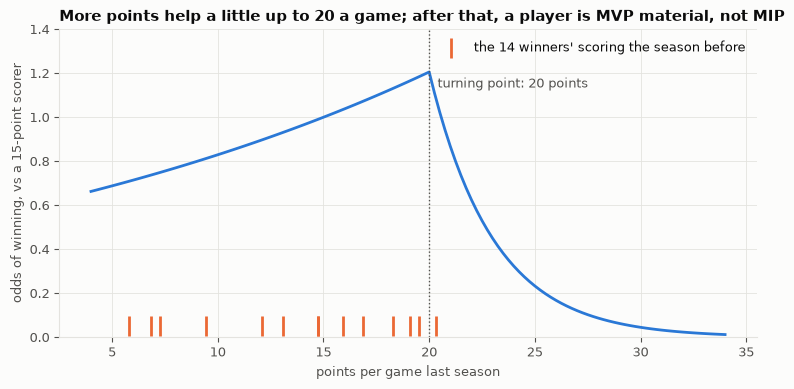

In [8]:

# what the fitted turning point means: odds of winning by last season's scoring, against a 15-point scorer
m_turn = ChoiceModel(USED, L2).fit(H)
b_lin = m_turn.coef_[USED.index("ppg_last")] / m_turn.std_[USED.index("ppg_last")]
b_turn = m_turn.coef_[USED.index("ppg_over_turn")] / m_turn.std_[USED.index("ppg_over_turn")]
ppg = np.linspace(4, 34, 121)
odds = np.exp(b_lin * (ppg - 15) + b_turn * np.clip(ppg - TURNING_POINT, 0, None))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ppg, odds, color=BLUE)
ax.axvline(TURNING_POINT, color=INK2, linewidth=1, linestyle=":")
ax.annotate(f"turning point: {TURNING_POINT} points", (TURNING_POINT, odds.max()), xytext=(6, -4), textcoords="offset points", fontsize=9, color=INK2, va="top")
w = H[H["mip"]]
ax.scatter(w["ppg_last"], np.full(len(w), 0.05), marker="|", s=200, color=ORANGE, label="the 14 winners' scoring the season before")
ax.set_xlabel("points per game last season"); ax.set_ylabel("odds of winning, vs a 15-point scorer")
ax.legend(frameon=False, loc="upper right"); ax.set_ylim(0, max(1.4, odds.max() * 1.15))
ax.set_title("More points help a little up to 20 a game; after that, a player is MVP material, not MIP", loc="left")
fig.savefig(FIG_DIR / "11_scoring_turning_point.png", dpi=150, bbox_inches="tight")
print(f"per point: {b_lin:+.3f} up to {TURNING_POINT}, {b_lin + b_turn:+.3f} above (log-odds)")
print({x: round(float(np.exp(b_lin * (x - 15) + b_turn * max(0, x - TURNING_POINT))), 2) for x in [10, 15, 20, 22, 25, 30]})


In [9]:
sens = {}
for name, feats in [("lean inputs + turning point (used)", USED), ("all inputs + turning point", LAST_SEASON + PROFILE + MOMENTUM + PRE_FORM + TURN + TEAM_CHANGE)]:
    for l2 in [0.1, 1.0, 3.0, 10.0]:
        sens[(name, f"λ = {l2:g}")] = scorecard(winner_ranks(feats, l2))
pd.DataFrame(sens).T.round(1)

seasons  winner #1  in top 3  \
lean inputs + turning point (used) λ = 0.1     14.0        1.0       4.0   
                                   λ = 1       14.0        1.0       2.0   
                                   λ = 3       14.0        1.0       1.0   
                                   λ = 10      14.0        0.0       3.0   
all inputs + turning point         λ = 0.1     14.0        1.0       3.0   
                                   λ = 1       14.0        1.0       4.0   
                                   λ = 3       14.0        1.0       3.0   
                                   λ = 10      14.0        0.0       2.0   

                                            in top 7  in top 20  median rank  \
lean inputs + turning point (used) λ = 0.1       7.0       10.0          7.0   
                                   λ = 1         8.0       11.0          7.0   
                                   λ = 3         7.0       11.0          7.0   
                                   λ = 10        7.0       10.0          6.5   
all inputs + turning point         λ = 0.1       7.0       11.0          6.5   
                                   λ = 1         8.0       11.0          5.5   
                                   λ = 3         7.0       10.0          7.0   
                                   λ = 10        8.0       10.0          6.0   

                                            times better than a blind guess  
lean inputs + turning point (used) λ = 0.1                              6.8  
                                   λ = 1                                7.1  
                                   λ = 3                                7.1  
                                   λ = 10                               6.1  
all inputs + turning point         λ = 0.1                              6.9  
                                   λ = 1                                7.2  
                                   λ = 3                                7.0  
                                   λ = 10                               6.0

In [10]:
used = ranks["+ a 20-point scorer left his team (not replaced)  ← used"]
winners = H[H["mip"]].set_index("season")["player_name"]
history = pd.DataFrame({"eventual winner": winners, "his preseason rank": used["rank"].astype(int), "candidates": used["n"].astype(int),
                        "model's chance for him": used["p"].astype(float).map("{:.1%}".format), "model's #1 pick": used["top_pick"]})
history

,eventual winner,his preseason rank,candidates,model's chance for him,model's #1 pick
2012-13,Paul George,13,359,1.5%,Glen Davis
2013-14,Goran Dragic,58,367,0.4%,Kawhi Leonard
2014-15,Jimmy Butler III,4,377,4.8%,Klay Thompson
2015-16,CJ McCollum,4,374,3.0%,Damian Lillard
2016-17,Giannis Antetokounmpo,5,376,3.3%,Steven Adams
2017-18,Victor Oladipo,9,369,2.5%,Ricky Rubio
2018-19,Pascal Siakam,4,365,3.9%,Zach LaVine
2019-20,Brandon Ingram,1,345,24.2%,Brandon Ingram
2020-21,Julius Randle,191,348,0.0%,Christian Wood
2021-22,Ja Morant,17,389,1.2%,Michael Porter Jr.


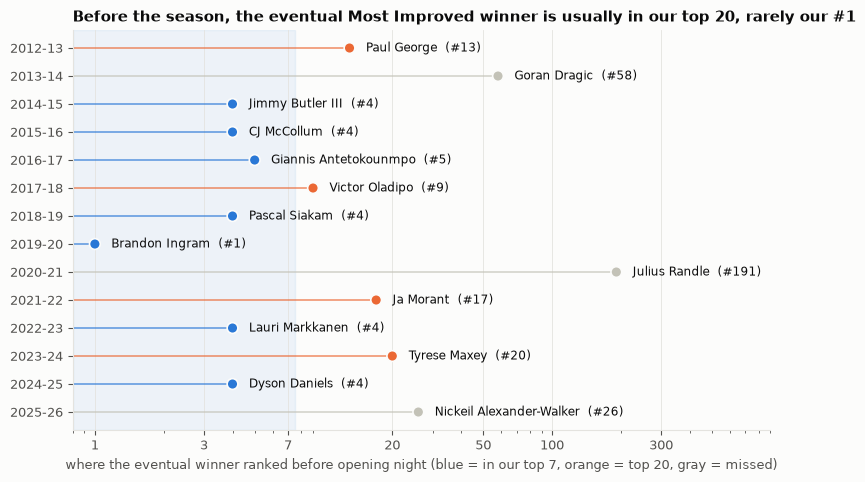

In [11]:
fig, ax = plt.subplots(figsize=(9, 5.2))
h = history.iloc[::-1]
y = np.arange(len(h)); rk = h["his preseason rank"].to_numpy()
col = np.where(rk <= 7, BLUE, np.where(rk <= 20, ORANGE, MUTED))
ax.axvspan(0.8, 7.5, color=BLUE, alpha=0.07); ax.hlines(y, 0.8, rk, color=col, linewidth=1.4, alpha=0.6)
ax.scatter(rk, y, s=60, color=col, edgecolor=SURFACE, linewidth=1.2, zorder=3)
for yi, r, n in zip(y, rk, h["eventual winner"]):
    ax.text(r * 1.18, yi, f"{n}  (#{r})", va="center", fontsize=8.5, color=INK)
ax.set_xscale("log"); ax.set_xlim(0.8, 900); ax.set_xticks([1, 3, 7, 20, 50, 100, 300], ["1", "3", "7", "20", "50", "100", "300"])
ax.set_yticks(y, h.index); ax.grid(axis="y", visible=False)
ax.set_xlabel("where the eventual winner ranked before opening night (blue = in our top 7, orange = top 20, gray = missed)")
ax.set_title("Before the season, the eventual Most Improved winner is usually in our top 20, rarely our #1", loc="left")
fig.savefig(FIG_DIR / "11_preseason_winner_ranks.png", dpi=150, bbox_inches="tight")

### 11B findings

**Preseason form makes a preseason prediction possible; knowing that a star has left makes it much better.**

| Inputs | Winner in our top 7 | In our top 20 | Median winner rank | vs a blind guess |
|---|---|---|---|---|
| Last season + profile | 3 of 14 | 5 | 44 | 1.8× |
| + momentum | 3 | 4 | 39.5 | 2.6× |
| + preseason form per 36 | 4 | 11 | 14.5 | 5.1× |
| + scoring turning point at 20 | 3 | 10 | 11.5 | 5.6× |
| **+ a 20-point scorer left his team, not replaced (used)** | **7** | **11** | **7** | **7.1×** |
| + preseason minute increases | 6 | 11 | 9 | 6.4× |
| + opportunity (team minutes freed up) | 7 | 10 | 6.5 | 6.8× |

Strict test (earlier seasons only, 9 seasons): the used model has the winner in its top 7 in 4 seasons, against 1 before the star flag (4.9× a blind guess, against 3.3×).

**The scoring turning point**
- **20 points a game fits best,** in both the leave-one-out and strict tests; 19 to 22 are close behind, so "around 20" is the finding.
- **What it means:** each point of last season's scoring adds a little up to 20 (a 20-point scorer has about 1.2× the odds of a 15-point scorer), then counts heavily against: ×0.62 at 22 points, ×0.23 at 25, ×0.04 at 30. No winner averaged more than 20.3 the season before.

**"A star left": yes/no, four bands or graded?**

| Version | Top 7 | Median | Fit | Strict top 7 | Strict fit |
|---|---|---|---|---|---|
| none | 3 | 11.5 | 5.6× | 1 | 3.3× |
| yes/no: a 20+ scorer left | 7 | 8 | 6.9× | 3 | 4.6× |
| **yes/no: left, and none arrived (used)** | **7** | **7** | **7.1×** | **4** | **4.9×** |
| four bands (20-22, 22-25, 25-27, 27+) | 8 | 4.5 | 9.4× | 3 | 5.2× |
| graded: the departed star's scoring | 5 | 9 | 6.6× | 3 | 4.2× |

- **The four bands score best but are memorising.** All six winners with a departed star sit between 22 and 27 points, so the bands model learns that losing a 21-point or a 28-point scorer *hurts* (weights −0.21 and −0.16) while losing a 23-point scorer helps (+0.54). By chance we would expect only about 0.5 and 0.2 winners in those two bands anyway. There is no basketball reason for that shape.
- **"Not replaced" is a little better than the plain flag** and matches the history: only one winner's team had also gained a 20-point scorer.
- **Graded versions were no better than yes/no.**

**Two inputs tested and left out:** preseason minute increases (worse on every measure) and opportunity (no better than the star flag it overlaps with).

**How good is this, honestly?**
- From about 375 candidates, the eventual winner was **in our top 7 in 7 of 14 seasons** (Butler, McCollum, Giannis, Siakam, Ingram as #1, Markkanen, Daniels) and in the top 20 in 11.
- Strict test (9 seasons): top 7 in 4, median rank 15. Better than before, but the strict test is still the weaker number.
- **The big misses remain Goran Dragić (58th) and Julius Randle (191st)**, plus Tyrese Maxey (20th): James Harden left Philadelphia only after the season started, so the flag couldn't see it in October.

**The penalty (λ):** λ = 3 as in notebook 10; the stability table in 11C shows the picks under every setting.

## 11C — The 2026-27 prediction

The model is refitted on all 14 past preseasons and applied to this one.

In [12]:
model = ChoiceModel(USED, L2).fit(H)
T = frame[frame["season"] == TARGET].reset_index(drop=True)
T["chance"] = model.predict_proba(T)
T["rank"] = T["chance"].rank(ascending=False, method="min").astype(int)
T = T.sort_values("rank").reset_index(drop=True)

NICE = {"mpg_last": "minutes last season", "ppg_last": "points last season", "usg_last": "usage last season", "team_win_pct_last": "team's wins last season",
        "age": "age", "second_year": "second-year discount", "new_team": "new team", "momentum_game_score": "improved last season",
        "late_surge_last": "strong finish last season", "pre_game_score_change": "preseason production per 36",
        "pre_volume_change": "preseason shot volume per 36", "pre_ts_change": "preseason shooting efficiency", "pre_minutes_up": "preseason minutes up",
        "ppg_over_turn": f"points above {TURNING_POINT} last season", "opportunity": "team minutes freed up",
        "star_left": "a 20-point scorer left (not replaced)"}
Z = pd.DataFrame(model._design(T), index=T.index, columns=USED)
contrib = ((Z - Z.mean()) * model.coef_).rename(columns=NICE)   # each input's push, vs the average candidate
T["why"] = [" + ".join(contrib.drop(columns=["second-year discount", f"points above {TURNING_POINT} last season"]).loc[i].nlargest(2).index) for i in T.index]   # the discount is never a reason to pick someone

print(f"{len(T)} candidates; the top 7 hold {T['chance'].head(7).sum():.0%} of the total chance (a blind guess would give them {7 / len(T):.0%})")
show = T.head(7)[["rank", "player_name", "chance", "age", "ppg_last", "mpg_last", "pre_mpg", "pts36_last", "pts36", "ts_last", "ts", "pre_minutes"]].copy()
show.columns = ["rank", "player", "chance", "age", "points last season", "minutes last season", "preseason minutes per game",
                "points per 36 last season", "points per 36 preseason", "true shooting last season", "true shooting preseason", "preseason minutes"]
print(show.round(3).to_string(index=False))
show.set_index("rank").style.format({"chance": "{:.1%}", "age": "{:.0f}", "true shooting last season": "{:.1%}", "true shooting preseason": "{:.1%}"}, precision=1)

402 candidates; the top 7 hold 32% of the total chance (a blind guess would give them 2%)
 rank            player  chance    age  points last season  minutes last season  preseason minutes per game  points per 36 last season  points per 36 preseason  true shooting last season  true shooting preseason  preseason minutes
    1     Rui Hachimura   0.091 28.981              11.471               28.338                      19.333                     14.572                   31.655                      0.620                    0.703               58.0
    2       Jalen Duren   0.079 23.207              19.500               28.257                      17.500                     24.843                   39.086                      0.688                    0.816               35.0
    3 Tyrese Haliburton   0.060 26.925              18.616               33.603                      18.000                     19.945                   32.000                      0.616                    0.636      

,player,chance,age,points last season,minutes last season,preseason minutes per game,points per 36 last season,points per 36 preseason,true shooting last season,true shooting preseason,preseason minutes
rank,,,,,,,,,,,
1,Rui Hachimura,9.1%,29,11.5,28.3,19.3,14.6,31.7,62.0%,70.3%,58.0
2,Jalen Duren,7.9%,23,19.5,28.3,17.5,24.8,39.1,68.8%,81.6%,35.0
3,Tyrese Haliburton,6.0%,27,18.6,33.6,18.0,19.9,32.0,61.6%,63.6%,54.0
4,Tristan da Silva,2.4%,26,9.9,24.7,21.8,14.4,27.3,57.6%,59.3%,87.0
5,Brandon Miller,2.3%,24,20.2,30.3,25.0,24.0,23.5,57.4%,49.3%,75.0
6,Devin Carter,2.2%,25,8.9,18.4,25.0,17.4,24.5,50.8%,73.0%,25.0
7,Luka Garza,2.1%,28,8.1,16.1,17.5,18.0,29.3,68.2%,60.2%,70.0


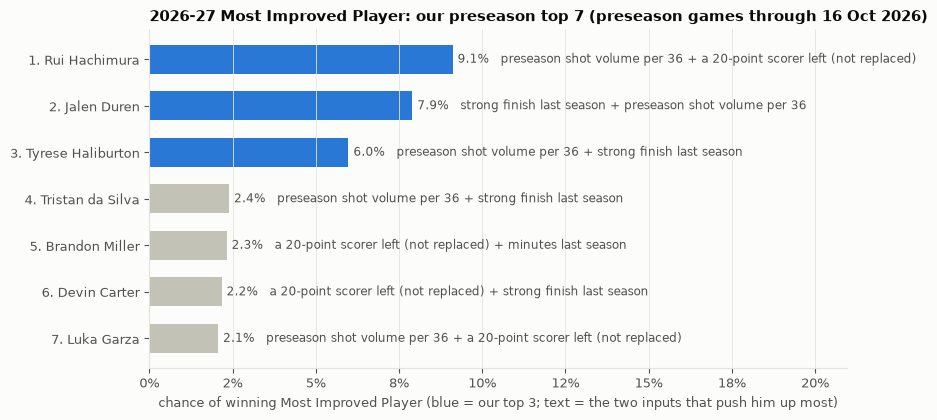

In [13]:
top = T.head(7).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(top))
ax.barh(y, top["chance"], color=[BLUE if r <= 3 else MUTED for r in top["rank"]], height=0.62)
for yi, (_, r) in zip(y, top.iterrows()):
    ax.text(r["chance"] + 0.0015, yi, f"{r['chance']:.1%}   {r['why']}", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, [f"{r['rank']}. {r['player_name']}" for _, r in top.iterrows()], fontsize=9.5)
ax.set_xlim(0, top["chance"].max() * 2.3); ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.grid(axis="y", visible=False); ax.set_xlabel("chance of winning Most Improved Player (blue = our top 3; text = the two inputs that push him up most)")
last_date = now["game_date"].max()
ax.set_title(f"{TARGET} Most Improved Player: our preseason top 7 (preseason games through {last_date:%d %b %Y})", loc="left")
fig.savefig(FIG_DIR / "11_mip_preseason_top7.png", dpi=150, bbox_inches="tight")

In [14]:
weights = pd.Series(model.coef_, index=[NICE[c] for c in USED]).sort_values()
print("model weights (per standard deviation of each input):"); print(weights.round(2).to_string())
reasons = contrib.head(7).copy(); reasons.index = T["player_name"].head(7)
print(reasons.T.reindex(weights.index[::-1]).round(2).to_string())
reasons.T.reindex(weights.index[::-1]).style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-1.5, vmax=1.5, axis=None)

model weights (per standard deviation of each input):
age                                     -0.61
points above 20 last season             -0.52
second-year discount                    -0.46
improved last season                     0.19
preseason production per 36              0.22
points last season                       0.23
usage last season                        0.26
preseason shooting efficiency            0.31
new team                                 0.31
team's wins last season                  0.43
a 20-point scorer left (not replaced)    0.51
strong finish last season                0.57
preseason shot volume per 36             0.73
minutes last season                      0.79
player_name                            Rui Hachimura  Jalen Duren  Tyrese Haliburton  Tristan da Silva  Brandon Miller  Devin Carter  Luka Garza
minutes last season                             0.55         0.55               1.05              0.21            0.74         -0.39       -0.61
preseason sh

player_name,Rui Hachimura,Jalen Duren,Tyrese Haliburton,Tristan da Silva,Brandon Miller,Devin Carter,Luka Garza
minutes last season,+0.55,+0.55,+1.05,+0.21,+0.74,-0.39,-0.61
preseason shot volume per 36,+2.08,+1.06,+1.57,+2.12,+0.33,+0.22,+2.00
strong finish last season,-0.33,+1.08,+1.36,+0.85,-0.04,+1.09,-0.19
a 20-point scorer left (not replaced),+1.59,-0.29,-0.29,-0.29,+1.59,+1.59,+1.59
team's wins last season,+0.39,+0.64,+0.29,+0.12,+0.08,-0.68,+0.50
new team,+0.44,-0.22,-0.22,-0.22,-0.22,+0.44,-0.22
preseason shooting efficiency,+0.19,+0.20,+0.05,+0.06,-0.22,+0.26,-0.21
usage last season,-0.17,+0.22,+0.12,-0.12,+0.42,+0.20,-0.08
points last season,+0.02,+0.32,+0.29,-0.04,+0.35,-0.07,-0.11
preseason production per 36,+0.47,+0.20,+0.25,+0.42,-0.10,+0.12,+0.39


In [15]:
# how stable is the top 7? refit under every setting from the sensitivity table and count appearances
settings = [(n, f, l2) for n, f in [("lean", USED), ("all", LAST_SEASON + PROFILE + MOMENTUM + PRE_FORM + TURN + TEAM_CHANGE)] for l2 in [0.1, 1.0, 3.0, 10.0]]
alt = {}
for n, f, l2 in settings:
    p = ChoiceModel(f, l2).fit(H).predict_proba(T)
    alt[f"{n}, λ = {l2:g}"] = p.rank(ascending=False, method="min").astype(int)
alt = pd.DataFrame(alt); alt.index = T["player_name"]
stable = alt.assign(**{"settings in top 7 (of 8)": (alt <= 7).sum(axis=1), "median rank": alt.median(axis=1)})
stable = stable[stable["settings in top 7 (of 8)"] > 0].sort_values(["settings in top 7 (of 8)", "median rank"], ascending=[False, True])
stable[["settings in top 7 (of 8)", "median rank"] + list(alt.columns)]

,settings in top 7 (of 8),median rank,"lean, λ = 0.1","lean, λ = 1","lean, λ = 3","lean, λ = 10","all, λ = 0.1","all, λ = 1","all, λ = 3","all, λ = 10"
player_name,,,,,,,,,,
Rui Hachimura,8,1.5,2,2,1,1,3,2,1,1
Jalen Duren,8,2.0,1,1,2,2,2,3,3,2
Tyrese Haliburton,8,3.0,3,3,3,3,1,1,2,3
Brandon Miller,6,5.5,6,5,5,11,7,5,5,9
Devin Carter,5,6.0,11,8,6,8,6,6,4,6
Stephon Castle,4,6.0,4,4,12,23,4,4,8,18
Tristan da Silva,4,7.5,13,6,4,9,19,10,6,5
Amen Thompson,3,12.0,7,10,23,33,5,7,14,27
Cooper Flagg,3,13.0,107,24,10,5,79,16,7,4


In [16]:
watch = ["Egor Dëmin", "Cooper Flagg", "Ryan Rollins", "Keyonte George", "Nickeil Alexander-Walker", "Luka Dončić"]
from unicorn.bref import normalize_name
key = frame[frame["season"] == TARGET].assign(k=lambda d: d["player_name"].map(normalize_name)).set_index("k")
rows = []
for name in watch:
    k = normalize_name(name)
    if k not in key.index:
        rows.append({"player": name, "note": "no preseason minutes yet / no baseline season"}); continue
    r = key.loc[k]; t = T[T["player_id"] == r["player_id"]]
    rows.append({"player": r["player_name"], "rank": int(t["rank"].iloc[0]) if len(t) else None, "chance": f"{t['chance'].iloc[0]:.2%}" if len(t) else "",
                 "note": "previous winner" if r["previous_winner"] else (f"{r['ppg_last']:.1f} points last season (above the turning point)" if r["ppg_last"] > TURNING_POINT else ("second-year player" if r["second_year"] else "")),
                 "preseason minutes": round(r["pre_minutes"]), "points per 36: last season → preseason": f"{r['pts36_last']:.1f} → {r['pts36']:.1f}"})
pd.DataFrame(rows).set_index("player")

,rank,chance,note,preseason minutes,points per 36: last season → preseason
player,,,,,
Egor Dëmin,327,0.01%,second-year player,85,14.8 → 16.9
Cooper Flagg,10,1.87%,21.0 points last season (above the turning point),74,22.6 → 28.7
Ryan Rollins,37,0.62%,,74,19.4 → 22.9
Keyonte George,273,0.02%,23.6 points last season (above the turning point),73,25.7 → 23.2
Nickeil Alexander-Walker,33,0.69%,previous winner,91,22.5 → 24.5
Luka Dončić,89,0.20%,33.5 points last season (above the turning point),60,33.6 → 35.4


In [17]:
# why two second-year players rank where they do: each input's push, against the average candidate
second = contrib.copy(); second.index = T["player_name"]
pair = second.loc[["Egor Dëmin", "Cooper Flagg"]].T.reindex(weights.index[::-1])
pair.loc["total"] = pair.sum()
print(pair.round(2).to_string())
T.set_index("player_name").loc[["Egor Dëmin", "Cooper Flagg"], ["age", "ppg_last", "mpg_last", "usg_last", "team_win_pct_last", "late_surge_last", "momentum_game_score", "pre_minutes"]].round(2)

player_name                            Egor Dëmin  Cooper Flagg
minutes last season                          0.25          1.05
preseason shot volume per 36                 0.69          0.89
strong finish last season                   -0.63          0.30
a 20-point scorer left (not replaced)       -0.29          1.59
team's wins last season                     -0.75         -0.55
new team                                    -0.22         -0.22
preseason shooting efficiency               -0.22          0.02
usage last season                           -0.01          0.38
points last season                          -0.02          0.38
preseason production per 36                 -0.03          0.31
improved last season                        -0.02         -0.02
second-year discount                        -1.28         -1.28
points above 20 last season                  0.18         -0.20
age                                          0.84          0.94
total                                   

,age,ppg_last,mpg_last,usg_last,team_win_pct_last,late_surge_last,momentum_game_score,pre_minutes
player_name,,,,,,,,
Egor Dëmin,20.92,10.31,25.10,0.18,0.24,-2.26,0.0,85.0
Cooper Flagg,20.12,21.04,33.56,0.26,0.32,1.68,0.0,74.0


### 11C findings

**Our 2026-27 Most Improved top 7** (complete preseason; revised model with the scoring turning point and the star flag):

| | Player | Chance | Why the model likes him |
|---|---|---|---|
| 1 | **Rui Hachimura** (Clippers) | 9.1% | Kawhi Leonard left the Clippers; new team; the biggest preseason shot-volume jump (32 points per 36) |
| 2 | **Jalen Duren** (Pistons) | 7.9% | Strong finish to last season, big preseason volume, age 23 |
| 3 | **Tyrese Haliburton** (Pacers) | 6.0% | Back from a missed season; strong finish to 2024-25; 34 minutes a game already |
| 4 | Tristan da Silva (Magic) | 2.4% | Preseason shot volume, strong finish to last season |
| 5 | Brandon Miller (Hornets) | 2.3% | LaMelo Ball left Charlotte; 30 minutes and 20.2 points last season, right at the turning point |
| 6 | Devin Carter (Celtics) | 2.2% | Jaylen Brown left Boston; new team; strong finish to last season |
| 7 | Luka Garza (Celtics) | 2.1% | Jaylen Brown left Boston; big preseason volume (29 points per 36) |

**How to read it**
- **Three favourites, then a wide field.** Hachimura, Duren and Haliburton are in the top 3 under every one of the 8 settings; the top 7 hold 32% of the chance.
- **The star flag reshaped the list.** Four of the seven are on a team that lost a 20-point scorer without replacing him: the Clippers (Kawhi Leonard), the Hornets (LaMelo Ball) and the Celtics (Jaylen Brown, twice). Teams that lost a star but gained one get no credit: Milwaukee (Giannis out, Tyler Herro in), Minnesota (Julius Randle out, LaMelo Ball in), Miami (Herro and Norman Powell out, Giannis in).
- **Both Duren and Haliburton played only 35–54 preseason minutes,** so their preseason numbers are discounted by about four-fifths.

**What the revisions changed**
- **Cooper Flagg is now 10th (1.9%):** Anthony Davis left Dallas, which outweighs being a second-year player just over the turning point (21.0).
- **Established scorers are in the pool and ranked where they belong:** Luka Dončić 89th, Keyonte George 273rd.
- **Previous winners are in:** Nickeil Alexander-Walker is 33rd.
- **Ryan Rollins fell to 37th:** Giannis left Milwaukee, but Tyler Herro arrived.

**Second-year players**
- **Egor Dëmin is 327th (0.01%).** The second-year discount is the biggest factor, plus a weak finish to last season and a team that won 24% of its games.
- This is the MIP question only; notebook 07's breakout outlook for Dëmin has no second-year discount.

**Next:** track these against notebook 12's live race.

## 11D — Backtest: what happened to each past preseason top 7?

11B asked one thing: where did the eventual winner rank? This asks the fuller question: **if we had published a top 7 every October, how would those seven players have done?**

- **Two versions of the past.** *Leave-one-out*: each season is predicted by a model trained on the other 13 (all 14 seasons, but the model has seen later seasons). *Strict*: trained on earlier seasons only, as it would have been at the time (9 seasons, 2017-18 on).
- **What counts as a hit.** The winner; a place in the real voting top 7; any vote at all; and a real scoring jump (+3 points a game or more over his baseline season).
- **Comparison.** The same model without the preseason inputs, and the average candidate.
- Voting results are used here only to score the picks, never to make them.

In [18]:
# BACKTEST
from unicorn.bref import all_mip_voting, attach_player_ids

votes = attach_player_ids(all_mip_voting(), regular).dropna(subset=["player_id"])
vote_rank = votes.set_index(["season", "player_id"])["vote_rank"]
act = regular_rates(regular).assign(ppg_act=lambda d: d["pts"] / d["games"], gspg_act=lambda d: d["game_score"] / d["games"])
B = H.merge(act[["player_id", "season_start", "ppg_act", "gspg_act", "games"]].rename(columns={"games": "games_act"}), on=["player_id", "season_start"], how="left")
B["ppg_change"] = B["ppg_act"] - B["ppg_last"]
B["game_score_change"] = B["gspg_act"] - B["gspg_last"]
B["vote_rank"] = [vote_rank.get((s, p), np.nan) for s, p in zip(B["season"], B["player_id"])]
B["jump"] = B["ppg_change"] >= 3            # a player who missed the season counts as no jump

def backtest_chance(features, l2, scheme):
    """Each candidate's preseason chance, from a model that never saw his season (loso) or any later one (strict)."""
    p = pd.Series(np.nan, index=B.index)
    for i, s in enumerate(sorted(B["season"].unique())):
        if scheme == "strict" and i < 5:
            continue
        train = B[B["season"] < s] if scheme == "strict" else B[B["season"] != s]
        test = B[B["season"] == s]
        p.loc[test.index] = ChoiceModel(features, l2).fit(train).predict_proba(test)
    return p

def top7(chance):
    d = B.assign(chance=chance).dropna(subset=["chance"])
    d["our_rank"] = d.groupby("season")["chance"].rank(ascending=False, method="first").astype(int)
    return d[d["our_rank"] <= 7], d

def report(chance):
    picks, pool = top7(chance)
    n = picks["season"].nunique()
    return {"seasons": n, "picks": len(picks), "seasons with the winner in our 7": int(picks["mip"].sum()),
            "our 7 in the real voting top 7 (per season)": (picks["vote_rank"] <= 7).sum() / n,
            "our 7 who got any vote (per season)": picks["vote_rank"].notna().sum() / n,
            "our 7 who jumped +3 points a game": picks["jump"].mean(), "all candidates who jumped +3": pool["jump"].mean(),
            "average points change, our 7": picks["ppg_change"].mean(), "average points change, all candidates": pool["ppg_change"].mean(),
            "average game score change, our 7": picks["game_score_change"].mean()}

NO_PRE = LAST_SEASON_LEAN + PROFILE + MOMENTUM + TURN
chances = {("leave-one-out", "with preseason form (used)"): backtest_chance(USED, L2, "loso"),
           ("leave-one-out", "without preseason"): backtest_chance(NO_PRE, L2, "loso"),
           ("strict", "with preseason form (used)"): backtest_chance(USED, L2, "strict"),
           ("strict", "without preseason"): backtest_chance(NO_PRE, L2, "strict")}
backtest = pd.DataFrame({k: report(v) for k, v in chances.items()})
print(f"real voting: on average {votes.groupby('season').size().mean():.0f} players get a vote each season")
backtest.round(2)

real voting: on average 22 players get a vote each season


leave-one-out  \
                                            with preseason form (used)   
seasons                                                          14.00   
picks                                                            98.00   
seasons with the winner in our 7                                  7.00   
our 7 in the real voting top 7 (per season)                       0.93   
our 7 who got any vote (per season)                               1.86   
our 7 who jumped +3 points a game                                 0.43   
all candidates who jumped +3                                      0.14   
average points change, our 7                                      2.58   
average points change, all candidates                            -0.15   
average game score change, our 7                                  1.65   

                                                               \
                                            without preseason   
seasons                                                 14.00   
picks                                                   98.00   
seasons with the winner in our 7                         4.00   
our 7 in the real voting top 7 (per season)              0.57   
our 7 who got any vote (per season)                      1.57   
our 7 who jumped +3 points a game                        0.23   
all candidates who jumped +3                             0.14   
average points change, our 7                             0.53   
average points change, all candidates                   -0.15   
average game score change, our 7                         0.20   

                                                                strict  \
                                            with preseason form (used)   
seasons                                                           9.00   
picks                                                            63.00   
seasons with the winner in our 7                                  4.00   
our 7 in the real voting top 7 (per season)                       1.11   
our 7 who got any vote (per season)                               1.56   
our 7 who jumped +3 points a game                                 0.41   
all candidates who jumped +3                                      0.15   
average points change, our 7                                      2.25   
average points change, all candidates                            -0.15   
average game score change, our 7                                  1.32   

                                                               
                                            without preseason  
seasons                                                  9.00  
picks                                                   63.00  
seasons with the winner in our 7                         2.00  
our 7 in the real voting top 7 (per season)              0.67  
our 7 who got any vote (per season)                      1.33  
our 7 who jumped +3 points a game                        0.22  
all candidates who jumped +3                             0.15  
average points change, our 7                             1.16  
average points change, all candidates                   -0.15  
average game score change, our 7                         0.76

In [19]:
picks, _ = top7(chances[("leave-one-out", "with preseason form (used)")])
strict_picks, _ = top7(chances[("strict", "with preseason form (used)")])
by_season = picks.groupby("season").agg(winner_in_our_7=("mip", "any"), in_real_top_7=("vote_rank", lambda v: int((v <= 7).sum())), got_a_vote=("vote_rank", "count"),
                                        jumped_3_points=("jump", "sum"), average_points_change=("ppg_change", "mean"))
by_season["best pick"] = [d.loc[d["ppg_change"].idxmax(), "player_name"] + f" ({d['ppg_change'].max():+.1f})" for _, d in picks.groupby("season")]
by_season["worst pick"] = [d.loc[d["ppg_change"].idxmin(), "player_name"] + f" ({d['ppg_change'].min():+.1f})" for _, d in picks.groupby("season")]
by_season.round(1)

,winner_in_our_7,in_real_top_7,got_a_vote,jumped_3_points,average_points_change,best pick,worst pick
season,,,,,,,
2012-13,False,0,3,2,0.6,Glen Davis (+5.8),Kwame Brown (-6.1)
2013-14,False,0,1,2,2.5,DeMarcus Cousins (+5.7),Evan Turner (+0.6)
2014-15,True,2,3,4,2.9,Jimmy Butler III (+6.9),Marcus Thornton (-1.8)
2015-16,True,1,2,4,4.2,CJ McCollum (+14.0),John Jenkins (-2.0)
2016-17,True,1,2,4,3.4,Giannis Antetokounmpo (+6.0),Victor Oladipo (-0.1)
2017-18,False,0,2,2,1.4,Aaron Gordon (+4.9),Myles Turner (-1.7)
2018-19,True,1,3,2,3.1,Pascal Siakam (+9.7),Troy Williams (-0.9)
2019-20,True,3,4,5,4.8,Shai Gilgeous-Alexander (+8.2),Tyus Jones (+0.6)
2020-21,False,1,1,1,1.8,Christian Wood (+7.9),Aaron Gordon (-2.1)


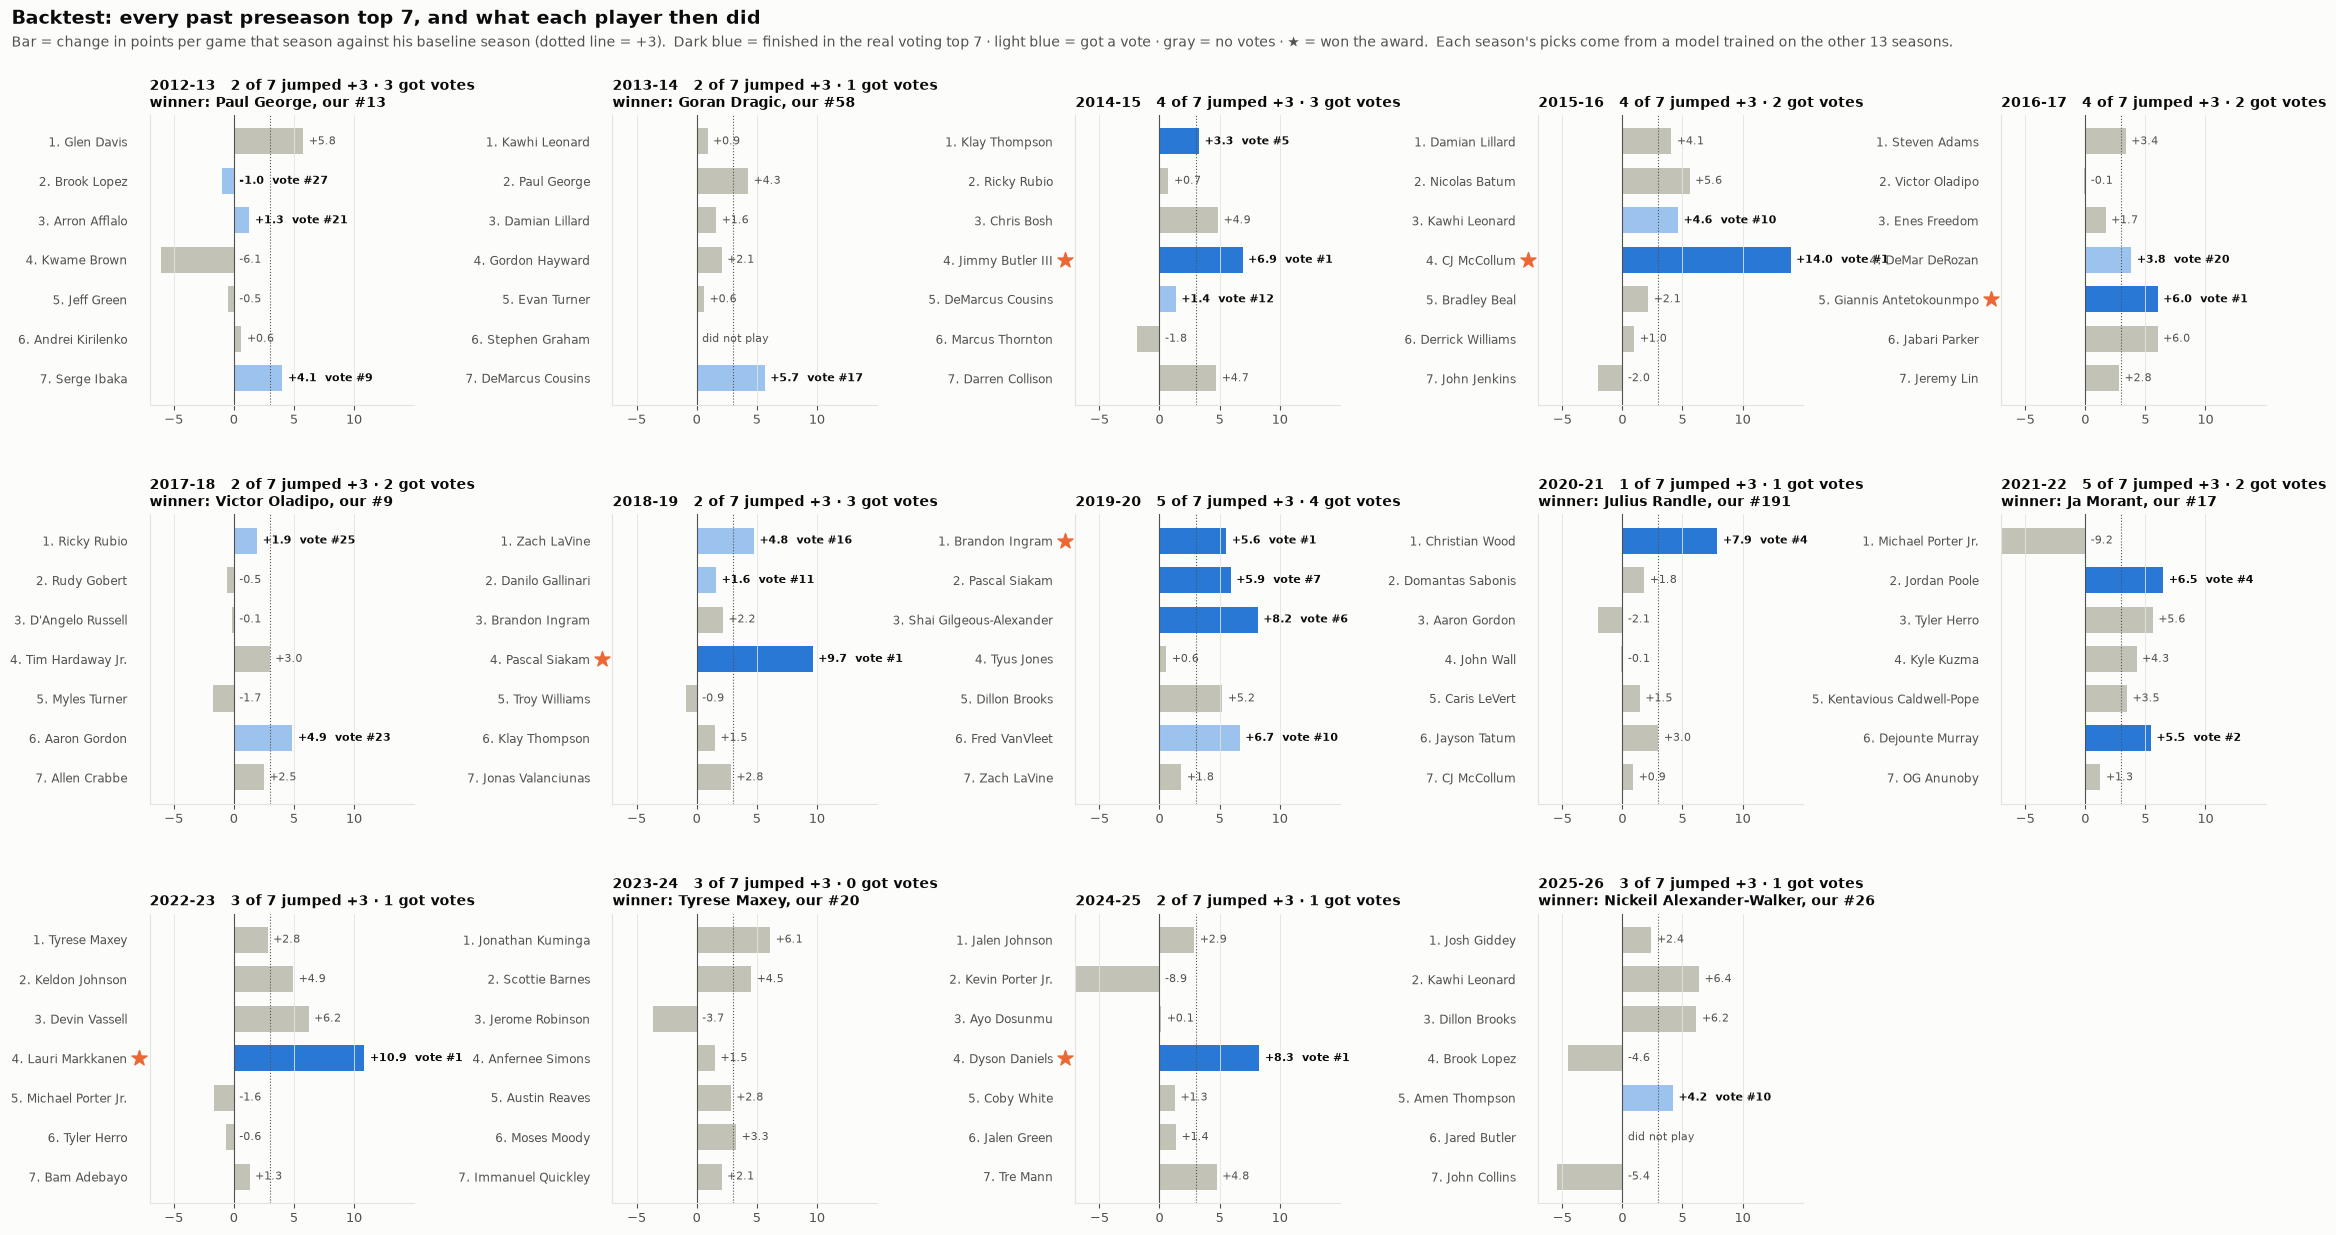

In [20]:
seasons = sorted(picks["season"].unique())
fig, axes = plt.subplots(3, 5, figsize=(23, 12.5))
for ax in axes.flat[len(seasons):]:
    ax.axis("off")
for ax, s in zip(axes.flat, seasons):
    d = picks[picks["season"] == s].sort_values("our_rank", ascending=False)
    y = np.arange(len(d)); v = d["ppg_change"].fillna(0).to_numpy()
    voted, top = d["vote_rank"].notna().to_numpy(), (d["vote_rank"] <= 7).to_numpy()
    ax.barh(y, v, color=np.where(top, BLUE, np.where(voted, "#9cc3ee", MUTED)), height=0.66)
    ax.axvline(0, color=INK2, linewidth=0.8); ax.axvline(3, color=INK2, linewidth=0.8, linestyle=":")
    for yi, (_, r) in zip(y, d.iterrows()):
        txt = "did not play" if pd.isna(r["ppg_change"]) else f"{r['ppg_change']:+.1f}" + (f"  vote #{int(r['vote_rank'])}" if pd.notna(r["vote_rank"]) else "")
        x = max(0 if pd.isna(r["ppg_change"]) else r["ppg_change"], 0)
        ax.annotate(txt, (x, yi), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8, color=INK if pd.notna(r["vote_rank"]) else INK2,
                    fontweight="bold" if pd.notna(r["vote_rank"]) else "normal")
        if r["mip"]:
            ax.scatter([-0.04], [yi], marker="*", s=130, color=ORANGE, clip_on=False, zorder=4, transform=ax.get_yaxis_transform())
    ax.set_yticks(y, [f"{r['our_rank']}. {r['player_name']}" for _, r in d.iterrows()], fontsize=8.5)
    ax.set_xlim(-7, 15); ax.set_xticks([-5, 0, 5, 10]); ax.grid(axis="y", visible=False); ax.tick_params(axis="y", length=0, pad=16)
    w = B[(B["season"] == s) & B["mip"]].iloc[0]
    miss = "" if d["mip"].any() else f"\nwinner: {w['player_name']}, our #{int(history.loc[s, 'his preseason rank'])}"
    ax.set_title(f"{s}   {int(d['jump'].sum())} of 7 jumped +3 · {int(voted.sum())} got votes{miss}", loc="left", fontsize=10)
fig.suptitle("Backtest: every past preseason top 7, and what each player then did", x=0.01, y=0.995, ha="left", fontsize=14, fontweight="bold")
fig.text(0.01, 0.965, "Bar = change in points per game that season against his baseline season (dotted line = +3).  Dark blue = finished in the real voting top 7 · light blue = got a vote · "
         "gray = no votes · ★ = won the award.  Each season's picks come from a model trained on the other 13 seasons.", ha="left", fontsize=10, color=INK2)
fig.subplots_adjust(left=0.07, right=0.99, top=0.91, bottom=0.04, wspace=0.75, hspace=0.38)
fig.savefig(FIG_DIR / "11_preseason_backtest_board.png", dpi=150, bbox_inches="tight")

In [21]:
# how do the picks do by rank, and does a higher preseason chance mean a bigger jump?
_, pool = top7(chances[("leave-one-out", "with preseason form (used)")])
pool["group"] = pd.cut(pool["our_rank"], [0, 3, 7, 20, 50, 1000], labels=["our 1–3", "our 4–7", "our 8–20", "our 21–50", "everyone else"])
by_rank = pool.groupby("group", observed=True).agg(players=("player_id", "size"), winners=("mip", "sum"), in_real_top_7=("vote_rank", lambda v: int((v <= 7).sum())),
                                                   got_a_vote=("vote_rank", "count"), share_jumped_3_points=("jump", "mean"), average_points_change=("ppg_change", "mean"))
by_rank.round(2)

,players,winners,in_real_top_7,got_a_vote,share_jumped_3_points,average_points_change
group,,,,,,
our 1–3,42,1,6,12,0.50,2.65
our 4–7,56,6,7,14,0.38,2.53
our 8–20,182,4,14,32,0.34,1.42
our 21–50,420,1,17,56,0.20,0.56
everyone else,4530,2,52,174,0.12,-0.34


### 11D findings

**The top 7 is a strong breakout list and, with the star flag, a reasonable award list.**

| Our preseason top 7 (14 seasons, 98 picks) | Our 7 | For comparison |
|---|---|---|
| Jumped +3 points a game or more | **43%** | 14% of all candidates |
| Average change in points a game | **+2.6** | −0.15 for all candidates |
| Got at least one MIP vote | 1.9 of 7 a season | about 0.4 if picked blindly (22 of 375 players get a vote) |
| Finished in the real voting top 7 | 0.9 of 7 a season | about 0.13 if picked blindly |
| Seasons with the winner in our 7 | **7 of 14** | |

- **Breakouts found.** More than two picks in five made a real scoring jump, three times the usual rate: CJ McCollum 2015-16 (+14.0), Lauri Markkanen 2022-23 (+10.9), Pascal Siakam 2018-19 (+9.7), Dyson Daniels 2024-25 (+8.3), Shai Gilgeous-Alexander 2019-20 (+8.2).
- **The strict version tells the same story:** 41% jumped +3 against 15%, +2.3 points on average, winner in our 7 in 4 of 9 seasons, 1.1 of our 7 in the real voting top 7.

**What the preseason inputs buy** (preseason form, the turning point and the star flag, against last season alone)
- **More real improvement:** 43% of picks jumped with them, 23% without (strict: 41% vs 22%).
- **More award hits too, now:** the winner in our 7 in 7 seasons against 4 (strict: 4 against 2).

**Where the list is strong and weak**

| Our rank | Players | Winners | Jumped +3 | Average points change |
|---|---|---|---|---|
| 1–3 | 42 | 1 | 50% | +2.7 |
| 4–7 | 56 | 6 | 38% | +2.5 |
| 8–20 | 182 | 4 | 34% | +1.4 |
| 21–50 | 420 | 1 | 20% | +0.6 |
| everyone else | 4,530 | 2 | 12% | −0.3 |

- **The top 7 now earns its name:** 7 of 14 winners came from it, mostly from ranks 4–7, and half of the top-3 picks made a real jump.
- **The typical bad pick** is still a fringe player with a loud preseason (Kwame Brown, John Jenkins) or a player who then got hurt (Michael Porter Jr. 2021-22, Kevin Porter Jr. 2024-25).

**For 2026-27:** Hachimura, Duren and Haliburton are the strongest picks; the rest of the top 7 and the next dozen are one pool.